# Aeroelastic flutter of a two-degree-of-freedom system
## Analytical and numerical investigation

This notebook accompanies the section **Aeroelastic Flutter: A Two-Degree-of-Freedom Model** in the vibration notes. The aim is to understand how motion-dependent aerodynamic loading can destabilise two otherwise stable structural modes, even in a steady airflow.

We distinguish three mechanisms: static divergence, negative aerodynamic damping (galloping), and flutter through aerodynamic coupling. The main investigation concerns the third mechanism. All aerodynamic coefficients used below are **illustrative**, not measurements for the depicted apparatus. The original structural parameters are retained.

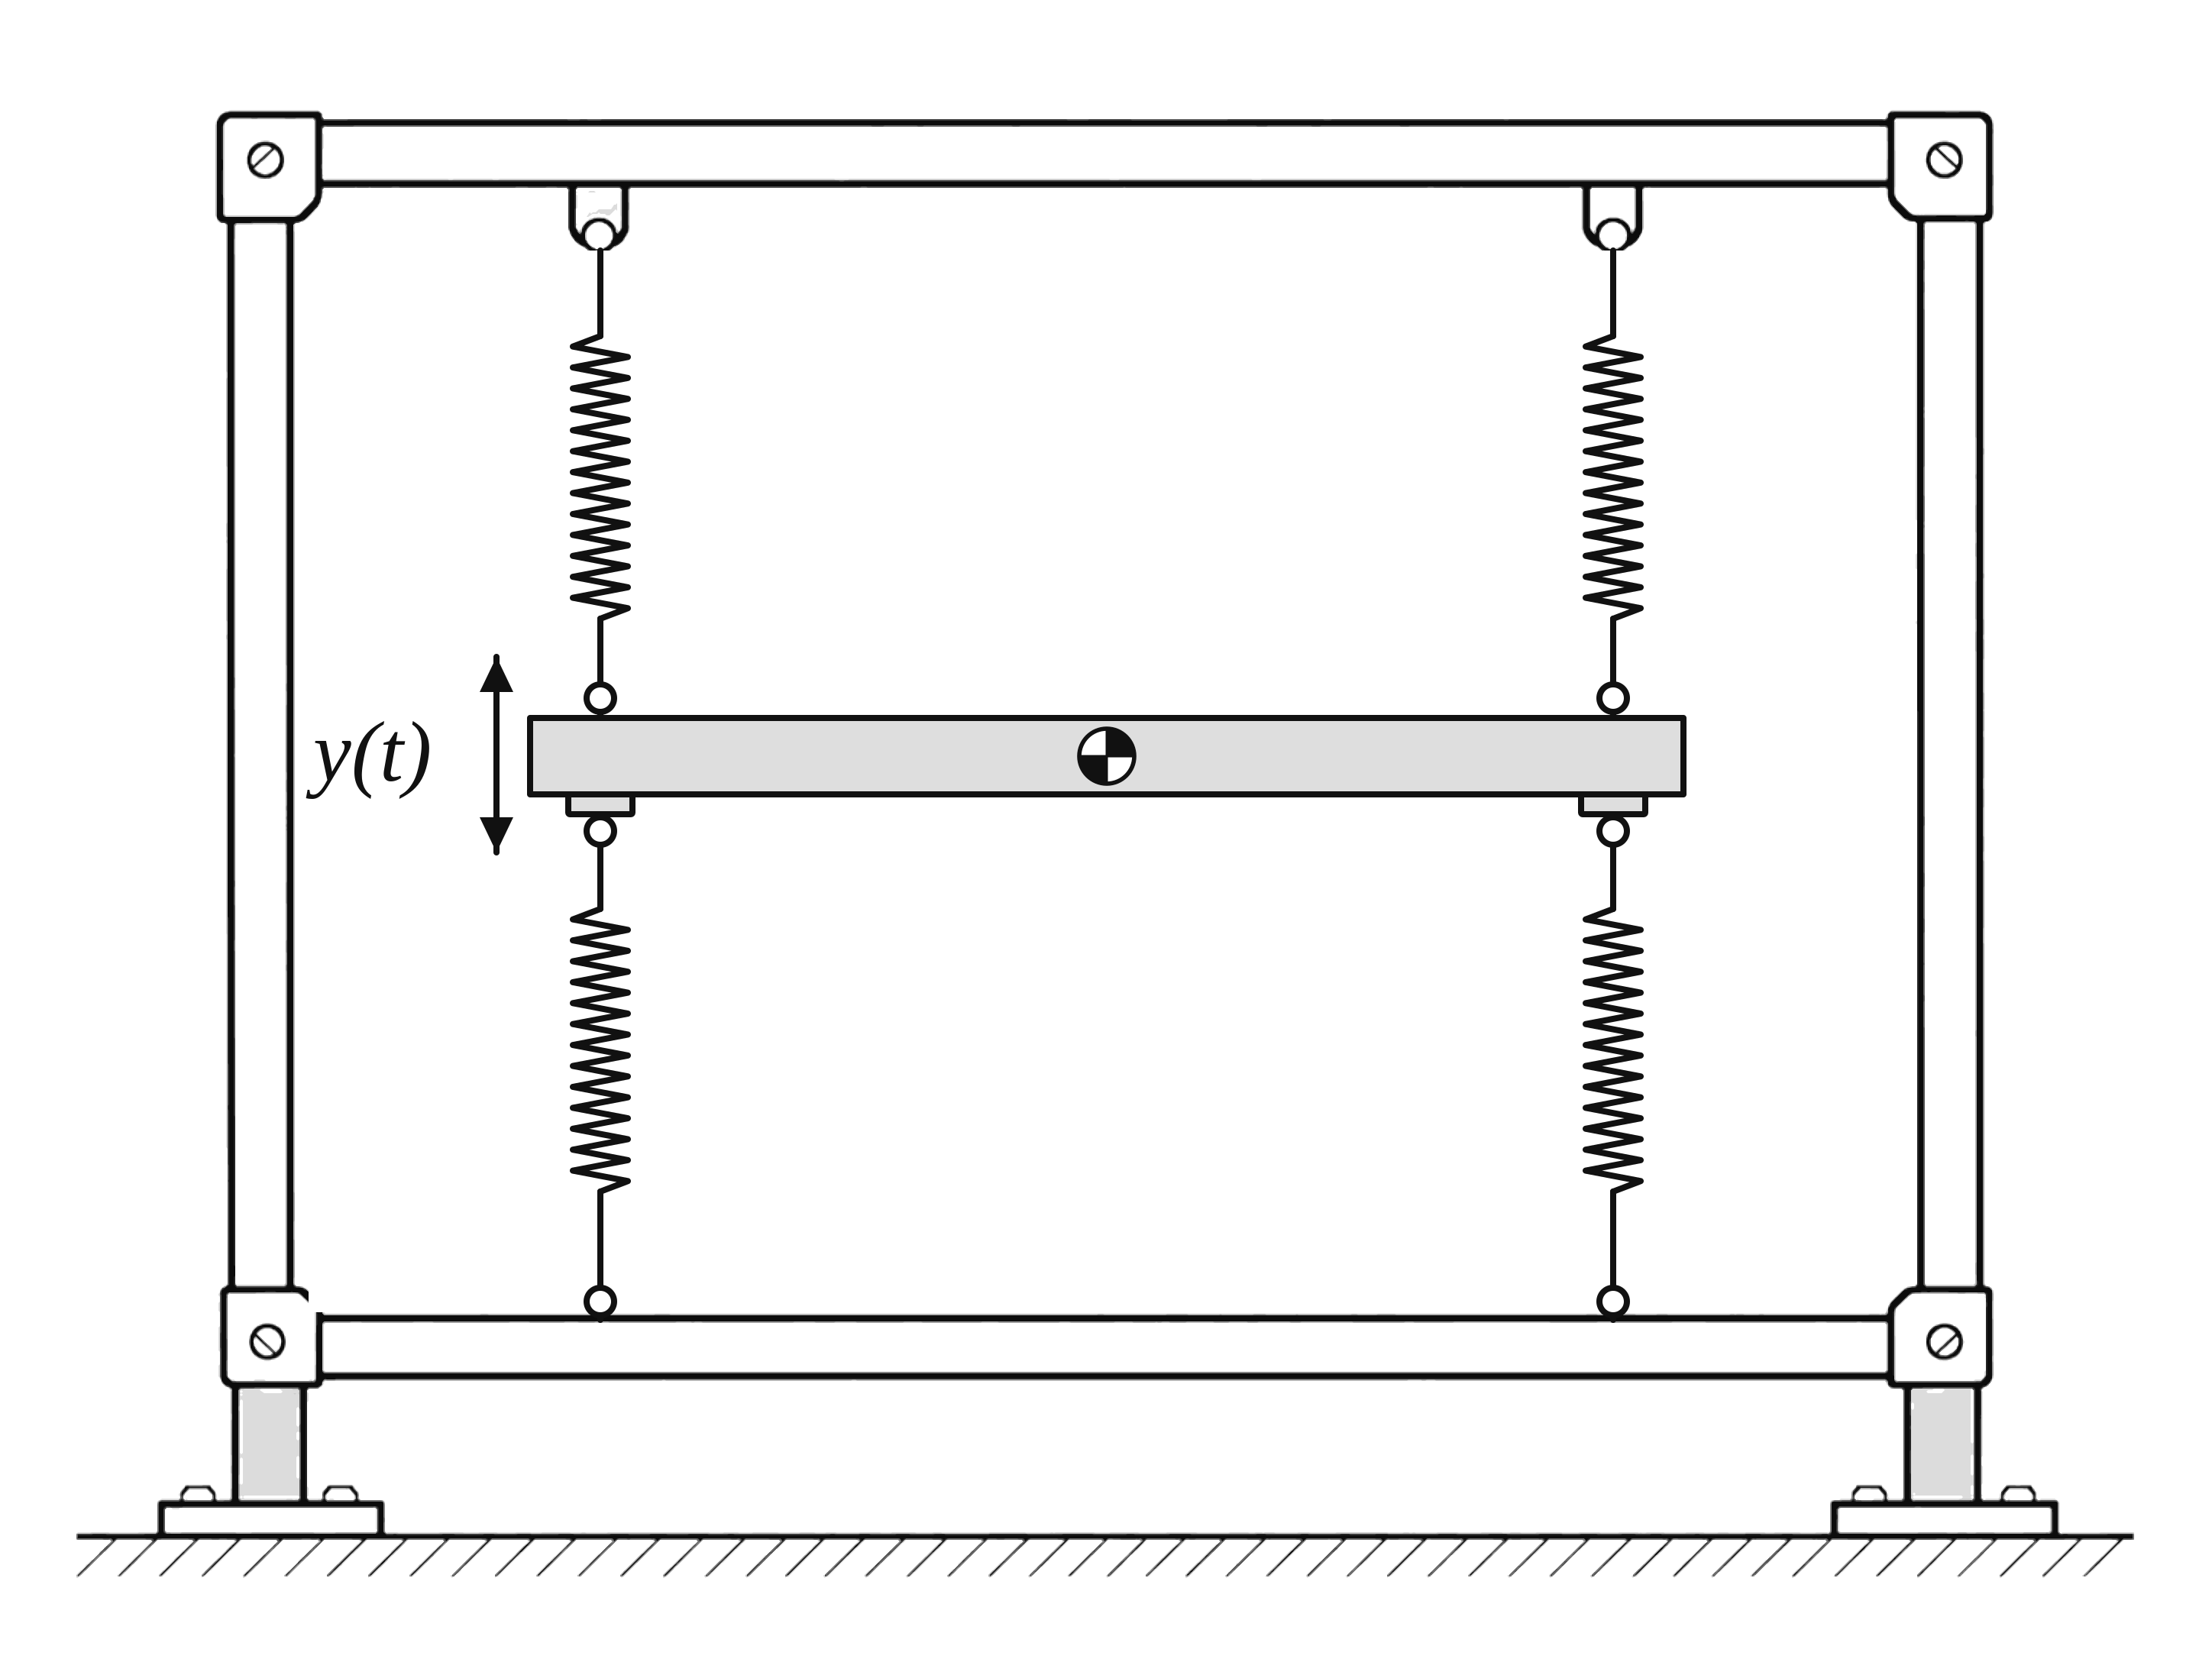

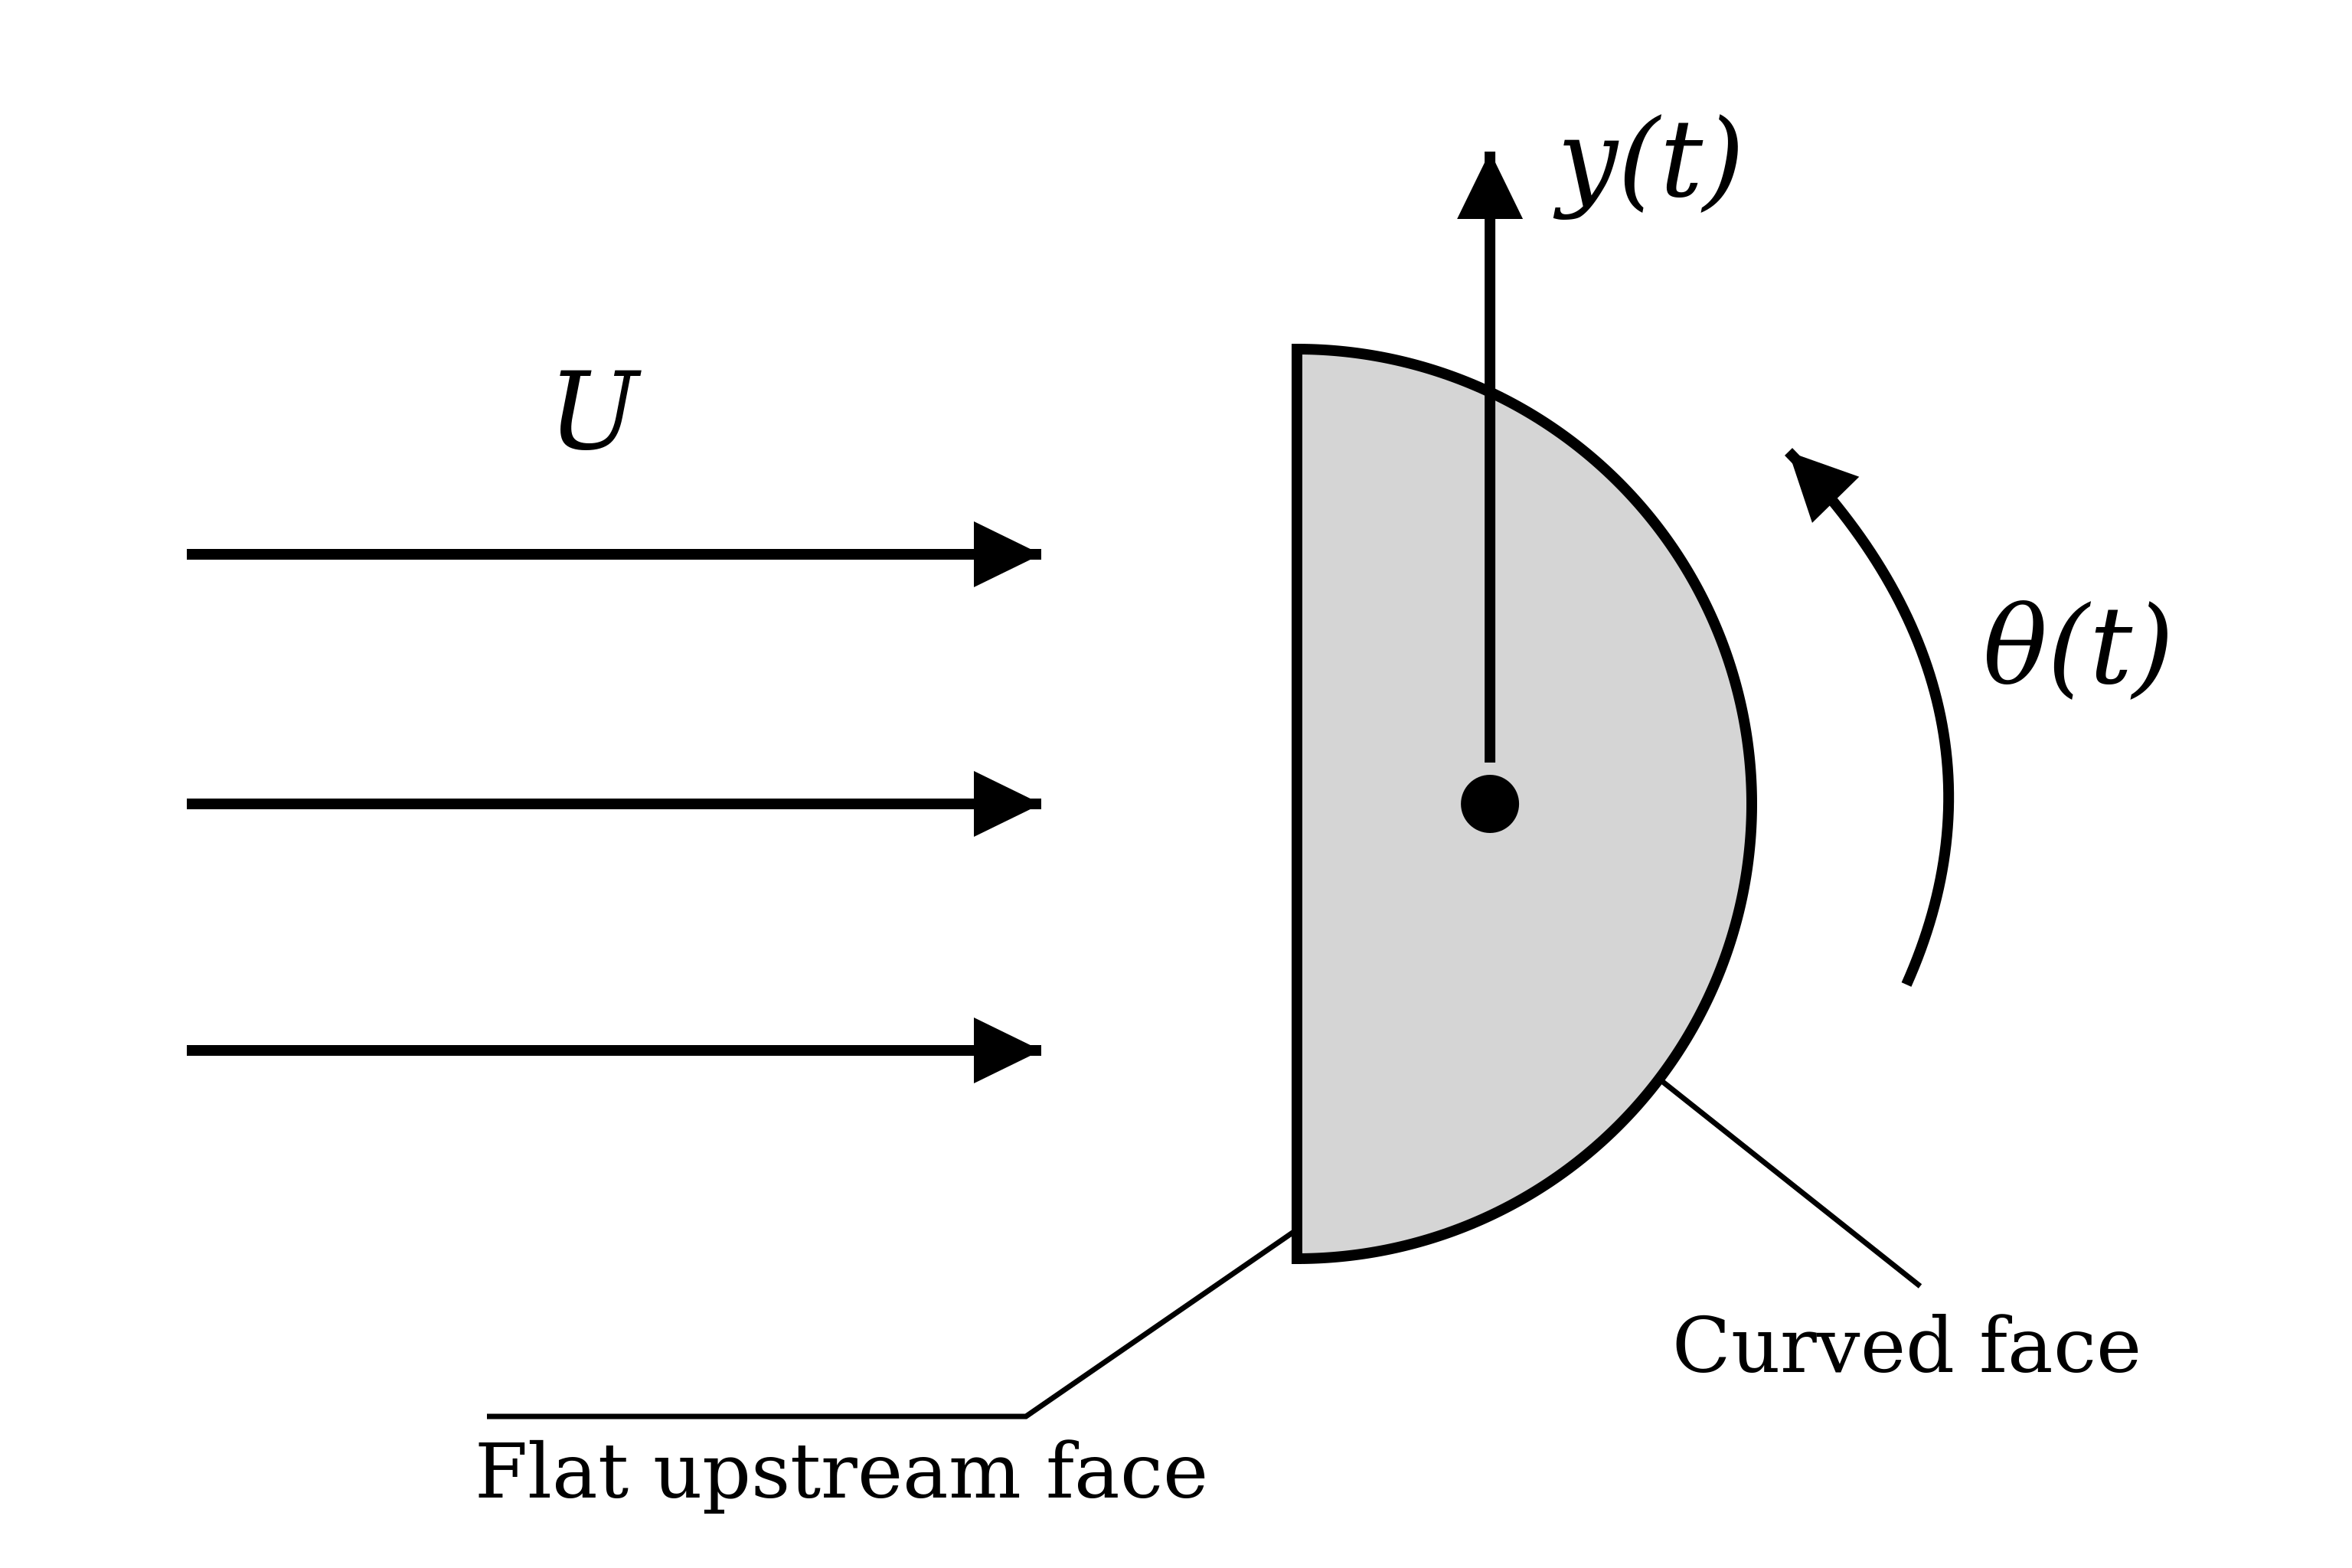

## 1. Physical model

The rigid body has a semicircular cross-section with its flat face facing upstream. Let $y(t)$ be the upward displacement of its centre of mass and $\theta(t)$ the counterclockwise rotation about its longitudinal axis. All other motions are constrained. Displacements are measured from static equilibrium.

The relative airflow is
$$
v_r=\begin{bmatrix}U\\-\dot y\end{bmatrix},\quad
U_r=\sqrt{U^2+\dot y^2},\quad
\beta=-\tan^{-1}(\dot y/U).
$$
The effective angle of attack is $\alpha_{\rm eff}=\theta-\beta\approx\theta+\dot y/U$. Under the quasi-steady approximation,
$$
F_D=\tfrac12\rho_f U_r^2 S C_D,\quad
F_L=\tfrac12\rho_f U_r^2 S C_L,\quad
T_a=\tfrac12\rho_f U_r^2 SD C_M.
$$
Drag acts along the relative airflow; positive lift acts perpendicular to it, counterclockwise. Thus $F_a=F_L\cos\beta+F_D\sin\beta$. Reflection symmetry under symmetric steady-flow conditions gives $C_L(0)=C_M(0)=0$. Linearising at fixed $U>0$ yields
$$
F_a=a_1(U)\theta-b_1(U)\dot y,\qquad
T_a=a_2(U)\theta+b_2(U)\dot y,
$$
where
$$
\begin{aligned}
a_1=A_1U^2,\quad &A_1=\tfrac12\rho_f S C_{L_\alpha},\\
a_2=A_2U^2,\quad &A_2=\tfrac12\rho_f SD C_{M_\alpha},\\
b_1=B_1U,\quad &B_1=\tfrac12\rho_f S(C_{D_0}-C_{L_\alpha}),\\
b_2=B_2U,\quad &B_2=A_2.
\end{aligned}
$$
Let $B_D=B_1+A_1=\tfrac12\rho_f S C_{D_0}>0$.

Momentum balance gives
$$
\begin{aligned}
M\ddot y+(C_y+b_1)\dot y+K_y y-a_1\theta&=0,\\
I\ddot\theta+C_\theta\dot\theta+(K_\theta-a_2)\theta-b_2\dot y&=0.
\end{aligned}
$$
The model neglects pitch-rate effects, apparent fluid inertia, wake memory and nonlinear saturation. The linearisation requires $|\theta|\ll1$ and $|\dot y|/U\ll1$; the no-flow model is obtained by setting the aerodynamic terms to zero. Constant aerodynamic coefficients are an additional assumption used in the speed investigations.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace
from pathlib import Path
from scipy.optimize import brentq, linear_sum_assignment
from scipy.sparse.linalg import expm_multiply
from IPython.display import display

plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm',
                     'font.size':11,'figure.facecolor':'white',
                     'axes.facecolor':'white','svg.fonttype':'path'})
figure_dir = Path('flutter_figures')
figure_dir.mkdir(exist_ok=True)
def save_figure(fig, name):
    for ext in ('svg','png'):
        fig.savefig(figure_dir / f'{name}.{ext}', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

@dataclass(frozen=True)
class Parameters:
    M: float = 1.0       # kg
    I: float = 0.02      # kg m^2
    K_y: float = 100.0   # N/m
    K_theta: float = 8.0 # N m/rad
    C_y: float = 0.2     # N s/m
    C_theta: float = 0.01 # N m s/rad
    rho_f: float = 1.225 # kg/m^3
    S: float = 0.1       # m^2
    D: float = 0.1       # m, illustrative reference diameter
    CL_alpha: float = 0.8
    CD_0: float = 1.6
    CM_alpha: float = -0.5

p = Parameters()
omega_y = np.sqrt(p.K_y/p.M)
omega_theta = np.sqrt(p.K_theta/p.I)
display(pd.DataFrame(vars(p), index=['Illustrative value']).T)
print(f'No-flow natural frequencies: {omega_y:.3f}, {omega_theta:.3f} rad/s')

## 2. Matrix model and characteristic roots

With $X=[y,\theta]^T$,
$$
\ddot X+\Gamma(U)\dot X+\Omega(U)X=0,
$$
$$
\Gamma=\begin{bmatrix}(C_y+b_1)/M&0\\-b_2/I&C_\theta/I\end{bmatrix},
\quad
\Omega=\begin{bmatrix}\omega_y^2&-a_1/M\\0&\omega_\theta^2-a_2/I\end{bmatrix}.
$$
For constant $U$, the Laplace transform gives
$$
\widehat X(s)=\Delta(s)^{-1}[(sI_{2\times2}+\Gamma)X(0)+\dot X(0)],
\qquad \Delta(s)=s^2 I_{2\times2}+s\Gamma+\Omega.
$$
The characteristic polynomial $|\Delta(s)|=s^4+p_3s^3+p_2s^2+p_1s+p_0$ is monic. Its coefficients are
$$
\begin{aligned}
p_3&=C_y/M+C_\theta/I+B_1U/M,\\
p_2&=\omega_y^2+\omega_\theta^2+C_yC_\theta/(MI)
+B_1C_\theta U/(MI)-A_2U^2/I,\\
p_1&=(C_y/M)\omega_\theta^2+(C_\theta/I)\omega_y^2
+(B_1/M)\omega_\theta^2 U-C_y A_2U^2/(MI)-A_2 B_D U^3/(MI),\\
p_0&=\omega_y^2(\omega_\theta^2-A_2 U^2/I).
\end{aligned}
$$
The cross term $-a_1 b_2 s/(MI)$ in the determinant is missed if the eigenvalues of $\Gamma$ and $\Omega$ are considered independently.

With state $\mathcal X=[X^T,\dot X^T]^T$,
$$
\dot{\mathcal X}=\mathcal A(U)\mathcal X,\qquad
\mathcal A=\begin{bmatrix}0&I_{2\times2}\\-\Omega&-\Gamma\end{bmatrix}.
$$
The eigenvalues of $\mathcal A$ are precisely the four characteristic roots. For distinct roots the displacement is a sum of terms $c_k\bar X_k e^{s_k t}$, where $\Delta(s_k)\bar X_k=0$.

In [ ]:
def constants(p):
    A1 = 0.5*p.rho_f*p.S*p.CL_alpha
    A2 = 0.5*p.rho_f*p.S*p.D*p.CM_alpha
    BD = 0.5*p.rho_f*p.S*p.CD_0
    return A1, A2, BD-A1, BD

def aero(U,p):
    A1,A2,B1,BD = constants(p)
    return A1*U**2,A2*U**2,B1*U,A2*U

def matrices(U,p):
    a1,a2,b1,b2 = aero(U,p)
    Gamma = np.array([[(p.C_y+b1)/p.M,0],[-b2/p.I,p.C_theta/p.I]])
    Omega = np.array([[p.K_y/p.M,-a1/p.M],[0,(p.K_theta-a2)/p.I]])
    return Gamma,Omega

def system_matrix(U,p):
    G,O = matrices(U,p)
    return np.block([[np.zeros((2,2)),np.eye(2)],[-O,-G]])

def coefficients(U,p):
    A1,A2,B1,BD = constants(p)
    M,I,Cy,Ct = p.M,p.I,p.C_y,p.C_theta
    wy2,wt2 = p.K_y/M,p.K_theta/I
    return np.array([1., Cy/M+Ct/I+B1*U/M,
        wy2+wt2+Cy*Ct/(M*I)+B1*Ct*U/(M*I)-A2*U**2/I,
        Cy/M*wt2+Ct/I*wy2+B1/M*wt2*U-Cy*A2*U**2/(M*I)-A2*BD*U**3/(M*I),
        wy2*(wt2-A2*U**2/I)])

def roots(U,p):
    return np.linalg.eigvals(system_matrix(U,p))

def sigma(U,p):
    return np.max(roots(U,p).real)

def routh(U,p):
    _,p3,p2,p1,p0 = coefficients(U,p)
    D2 = p3*p2-p1
    R = p1*D2-p3*p3*p0
    return np.array([p3,D2,R,p0])

def match(a,b):
    i,j = linear_sum_assignment(abs(a[:,None]-b[None,:]))
    return b[j[np.argsort(i)]]

def track(U_values,p):
    z = np.empty((len(U_values),4),complex)
    z[0] = np.sort_complex(roots(U_values[0],p))
    for k,U in enumerate(U_values[1:],1):
        z[k] = match(z[k-1],roots(U,p))
    return z

# Independent verification of polynomial and state-space roots.
for U in (0,5,20,40,80):
    r = roots(U,p)
    rp = match(r,np.roots(coefficients(U,p)))
    np.testing.assert_allclose(r,rp,rtol=1e-8,atol=1e-8)
    np.testing.assert_allclose(np.poly(system_matrix(U,p)),coefficients(U,p),
                               rtol=1e-8,atol=1e-8)
print('Polynomial and state-space eigenvalues agree.')

## 3. Stability for small and large airflow speeds

For $U=0$,
$$
|\Delta(s)|=(s^2+C_y s/M+\omega_y^2)
(s^2+C_\theta s/I+\omega_\theta^2).
$$
With strictly positive structural stiffness and damping, all roots lie in the open left half-plane. By continuity, the system remains asymptotically stable for sufficiently small $U$.

At large $U$, the leading terms of $p_3,p_2,p_1,p_0$ are respectively $B_1 U/M$, $-A_2U^2/I$, $-A_2B_DU^3/(MI)$ and $-A_2\omega_y^2U^2/I$. Substituting $s=U\lambda$ and dividing by $U^4$ gives the limiting polynomial
$$
\lambda\left(\lambda^3+\frac{B_1}{M}\lambda^2
-\frac{A_2}{I}\lambda-\frac{A_2B_D}{MI}\right).
$$
A limiting root with positive real part guarantees eventual instability. A zero limiting root requires higher-order analysis. For $A_2\ne0$, the zero root is simple and the slow root satisfies $s\sim -K_y/(B_D U)$, obtained by balancing $p_1s+p_0$.

Three sufficient conditions for eventual instability are:
1. $A_2>0$: $p_0<0$ for $U>U_d=\sqrt{K_\theta/A_2}$, so a positive real root exists.
2. $B_1<0$: eventually $p_3<0$ and the sum of the real parts of the roots is positive.
3. $A_2<0,\ B_1>0,\ A_1>0$: the limiting cubic has positive coefficients but fails the cubic Hurwitz inequality, since $B_1<B_D$. It therefore has an unstable complex pair. Here both diagonal damping and stiffness increase; static divergence is impossible.

These are sufficient, not exhaustive, conditions. The large-speed limit is a formal property of the constant-coefficient model, not a claim that quasi-steady aerodynamics remains valid at arbitrarily high speed.

In [ ]:
A1,A2,B1,BD = constants(p)
limiting = np.roots([1,B1/p.M,-A2/p.I,-A2*BD/(p.M*p.I),0])
rows=[]
for U in (1e-3,1e-2,1e-1):
    rows.append({'U':U,'sigma':sigma(U,p),
                 'max root error from U=0':max(abs(match(roots(0,p),roots(U,p))-roots(0,p)))})
display(pd.DataFrame(rows))
rows=[]
for U in (100,1000,10000):
    scaled = match(limiting,roots(U,p)/U)
    slow = roots(U,p)[np.argmin(abs(roots(U,p)))]
    rows.append({'U':U,'max scaled root error':max(abs(scaled-limiting)),
                 'U times slow root (real)':(U*slow).real})
print('Limiting roots:',limiting)
print('Predicted U times slow root:',-p.K_y/BD)
display(pd.DataFrame(rows))

## 4. Critical airflow speeds and the Routh–Hurwitz criterion

Define $\sigma(U)=\max_k\operatorname{Re}s_k(U)$. It is continuous. Initial stability and eventual instability imply a boundary with $\sigma=0$, but continuity alone does not distinguish touching from crossing.

For a nonzero-frequency boundary, substitute $s=i\omega_f$:
$$
\omega_f^4-p_2\omega_f^2+p_0=0,\qquad
p_1-p_3\omega_f^2=0.
$$
For $p_3,p_1>0$,
$$
\omega_f=\sqrt{p_1/p_3},\qquad
R(U)=p_3p_2p_1-p_1^2-p_3^2p_0=0.
$$
If also $p_0>0$, the polynomial factors as
$$
(s^2+\omega_f^2)(s^2+p_3s+p_0/\omega_f^2),
$$
so the other two roots are strictly stable.

The quartic Routh array has first column
$$
1,\quad p_3,\quad \frac{D_2}{p_3},\quad \frac{R}{D_2},\quad p_0,
\qquad D_2=p_3p_2-p_1.
$$
Thus asymptotic stability holds iff $p_3,D_2,R,p_0>0$. At a simple flutter boundary with the other inequalities strict, a change of $R$ from positive to negative gives two right-half-plane roots. $R'(U_f)<0$ is sufficient for this sign change, not necessary.

The numerical search below brackets sign-changing spectral-abscissa roots on a finite grid. It verifies the boundary through the polynomial and reports the crossing type. It does not certify absence of arbitrarily narrow unstable intervals or tangential contacts; for the chosen examples, the plotted curves and independent Routh checks corroborate the first crossing.

In [ ]:
def first_crossing(p,U_max=100.,N=2501):
    us=np.linspace(0,U_max,N)
    g=np.array([sigma(u,p) for u in us])
    for j in range(len(us)-1):
        if g[j]<0 and g[j+1]>=0:
            return brentq(lambda u:sigma(u,p),us[j],us[j+1],xtol=1e-11)
    return np.nan

def divergence_speed(p):
    A2=constants(p)[1]
    return np.sqrt(p.K_theta/A2) if A2>0 else np.inf

cases = {
    'Coupled flutter':p,
    'Static divergence':replace(p,CL_alpha=0.,CM_alpha=0.5),
    'Negative damping':replace(p,CL_alpha=2.,CM_alpha=0.)
}
critical={}
rows=[]
for name,par in cases.items():
    uc=first_crossing(par)
    critical[name]=uc
    r=roots(uc,par)
    crossing=r[np.argmax(r.real)]
    _,p3,p2,p1,p0=coefficients(uc,par)
    freq=abs(crossing.imag)
    rows.append({'Mechanism':name,'U_cr (m/s)':uc,'omega at crossing (rad/s)':freq,
                 'U_d (m/s)':divergence_speed(par),'R(U_cr)':routh(uc,par)[2],
                 'sigma below':sigma(.99*uc,par),'sigma above':sigma(1.01*uc,par)})
display(pd.DataFrame(rows).round(6))

U_f=critical['Coupled flutter']
_,p3,p2,p1,p0=coefficients(U_f,p)
omega_f=np.sqrt(p1/p3)
U_R=brentq(lambda u:routh(u,p)[2],.8*U_f,1.2*U_f)
Rprime=(routh(U_f+1e-3,p)[2]-routh(U_f-1e-3,p)[2])/(2e-3)
np.testing.assert_allclose(U_R,U_f,atol=1e-7)
assert p3>0 and p1>0 and p0>0 and Rprime<0
print(f'Coupled flutter: U_f={U_f:.6f} m/s, omega_f={omega_f:.6f} rad/s')
print(f'Independent R=0 solution: {U_R:.6f}; R derivative: {Rprime:.6g}')
print('Roots at boundary:',roots(U_f,p))

## 5. Numerical root loci

Here the parameter being varied is the airflow speed, rather than a feedback gain. The four roots are matched between successive speed samples by minimum total distance. This is a numerical labelling convention: at repeated roots individual branches cannot be uniquely distinguished.

The three examples isolate the mechanisms using the same structural parameters. For divergence we set $C_{L_\alpha}=0$; for negative damping we set $C_{M_\alpha}=0$, so the examples are intentionally simplified. In the coupled case both aerodynamic couplings are nonzero.

In [ ]:
styles=['-','--','-.',':']
for name,par in cases.items():
    uc=critical[name]
    us=np.linspace(0,1.4*uc,1001)
    Z=track(us,par)
    fig,ax=plt.subplots(figsize=(7,5))
    for k,ls in enumerate(styles):
        ax.plot(Z[:,k].real,Z[:,k].imag,ls,color='black',label=f'Branch {k+1}')
        j=700
        ax.annotate('',xy=(Z[j+15,k].real,Z[j+15,k].imag),
                    xytext=(Z[j,k].real,Z[j,k].imag),
                    arrowprops=dict(arrowstyle='->',color='black'))
    ax.scatter(Z[0].real,Z[0].imag,facecolors='white',edgecolors='black',s=55,zorder=4,label='U=0')
    rc=roots(uc,par)
    ax.scatter(rc.real,rc.imag,marker='x',color='black',s=65,zorder=5,label='Critical speed')
    ax.axvline(0,color='0.5',lw=.8)
    ax.axhline(0,color='0.7',lw=.7)
    ax.set(xlabel=r'$\mathrm{Re}(s)$ [1/s]',ylabel=r'$\mathrm{Im}(s)$ [rad/s]',
           title=f'{name}: increasing airflow speed')
    ax.legend(fontsize=8); ax.grid(alpha=.2)
    save_figure(fig,'root_locus_'+name.lower().replace(' ','_'))

In [ ]:
fig,ax=plt.subplots(figsize=(8,4.5))
for (name,par),ls in zip(cases.items(),styles):
    uc=critical[name]
    u=np.linspace(0,1.4*uc,600)
    ax.plot(u/uc,[sigma(v,par) for v in u],ls,color='black',label=name)
ax.axhline(0,color='0.5',lw=.8);ax.axvline(1,color='0.5',lw=.8)
ax.set(xlabel=r'$U/U_{cr}$',ylabel=r'$\sigma(U)$ [1/s]',title='Growth and decay rates')
ax.legend();ax.grid(alpha=.2)
save_figure(fig,'spectral_abscissa_all_cases')

fig,ax=plt.subplots(figsize=(7,4))
for ratio,marker in zip((.8,1.,1.2),('o','x','^')):
    r=roots(ratio*U_f,p)
    ax.scatter(r.real,r.imag,marker=marker,facecolors='none' if marker!='x' else None,
               color='black',label=fr'$U={ratio:g}U_f$')
ax.axvline(0,color='0.5');ax.set(xlabel=r'$\mathrm{Re}(s)$ [1/s]',
    ylabel=r'$\mathrm{Im}(s)$ [rad/s]',title='Roots around coupled flutter onset')
ax.legend();ax.grid(alpha=.2)
save_figure(fig,'roots_near_flutter')

In [ ]:
us=np.linspace(0,1.5*U_f,600)
H=np.array([routh(u,p) for u in us])
fig,ax=plt.subplots(figsize=(8,4.5))
for j,(label,ls) in enumerate(zip(['$p_3$','$D_2$','$R$','$p_0$'],styles)):
    ax.plot(us/U_f,H[:,j]/abs(H[0,j]),ls,color='black',label=label)
ax.axhline(0,color='0.5');ax.axvline(1,color='0.5')
ax.set(xlabel=r'$U/U_f$',ylabel='Hurwitz quantity / initial magnitude',
       title='Routh–Hurwitz verification (normalised quantities)')
ax.set_yscale('symlog',linthresh=1)
ax.legend();ax.grid(alpha=.2)
save_figure(fig,'routh_hurwitz')
# In this case both matrices have positive eigenvalues throughout.
for u in us:
    G,O=matrices(u,p)
    assert min(np.linalg.eigvals(G).real)>0 and min(np.linalg.eigvals(O).real)>0
    if abs(sigma(u,p))>1e-8:
        assert (sigma(u,p)<0)==np.all(routh(u,p)>0)
print('Positive eigenvalues of Gamma and Omega do not guarantee coupled stability.')

## 6. Negligible structural damping

Let $C_y=C_\theta=0$, retaining aerodynamic damping and coupling. Set
$$
A=\omega_y^2,\quad B=(K_\theta-a_2)/I,\quad d=b_1/M,\quad h=a_1b_2/(MI).
$$
Then
$$
|\Delta(s)|=s^4+ds^3+(A+B)s^2+(dB-h)s+AB,
$$
$$
D_2=dA+h,\qquad R=h[d(B-A)-h].
$$
For $d>0$, asymptotic stability requires $AB>0$, $D_2>0$ and $R>0$. At $U=0$ the undamped system has purely imaginary roots, so initial asymptotic stability cannot be inferred by continuity.

For the coupled-flutter signs $A_2<0$, $0<A_1<B_D$, one has $d>0$, $h<0$ at positive speed and
$$
d(B-A)-h=\frac{B_1}{M}(\omega_\theta^2-\omega_y^2)U
-\frac{A_2B_D}{MI}U^3.
$$
If $\omega_\theta\ge\omega_y$, this expression is positive for $U>0$, and $R<0$: the system is unstable at every positive speed. If $\omega_\theta<\omega_y$, the expression is initially negative and changes sign at
$$
U_{f,0}=\sqrt{\frac{I B_1(\omega_y^2-\omega_\theta^2)}{-A_2 B_D}}.
$$
At this speed $B>0$, $D_2=dB>0$ and the other Hurwitz inequalities hold. Below it, $D_2>0$ (it decreases relative to $d$ with $U^2$ but is positive at the boundary). Thus in the reversed-frequency case there is a finite stable interval for positive $U$. The no-flow endpoint itself is only marginally stable.

This contrasts with the positive-structural-damping case. It also shows why simply setting structural damping to zero in a critical-speed formula may alter the qualitative conclusion.

In [ ]:
p0=replace(p,C_y=0.,C_theta=0.)
pr=replace(p0,K_theta=1.)
A1,A2,B1,BD=constants(pr)
U_zero=np.sqrt(pr.I*B1*(pr.K_y/pr.M-pr.K_theta/pr.I)/(-A2*BD))
print(f'Reversed-frequency zero-damping prediction: {U_zero:.6f} m/s')
for par in (p0,pr):
    for u in (0.1,5.,15.,40.):
        a1,a2,b1,b2=aero(u,par)
        A=par.K_y/par.M; B=(par.K_theta-a2)/par.I
        d=b1/par.M; h=a1*b2/(par.M*par.I)
        np.testing.assert_allclose(routh(u,par)[2],h*(d*(B-A)-h),rtol=1e-8,atol=1e-8)
np.testing.assert_allclose(sigma(U_zero,pr),0,atol=1e-8)
fig,ax=plt.subplots(figsize=(8,4.5))
for par,label,ls in [(p0,r'$\omega_\theta>\omega_y$','-'),(pr,r'$\omega_\theta<\omega_y$','--')]:
    u=np.linspace(0,45,800)
    ax.plot(u,[sigma(v,par) for v in u],ls,color='black',label=label)
ax.axhline(0,color='0.5');ax.axvline(U_zero,color='0.5',ls=':')
ax.set(xlabel='U [m/s]',ylabel=r'$\sigma$ [1/s]',title='Zero structural damping')
ax.legend();ax.grid(alpha=.2)
save_figure(fig,'zero_structural_damping')

etas=np.geomspace(1e-4,1,60)
# Use an R-polynomial search for the main case; verify each positive root.
def R_polynomial(par):
    from numpy.polynomial import Polynomial as Poly
    A1,A2,B1,BD=constants(par)
    M,I,Cy,Ct=par.M,par.I,par.C_y,par.C_theta
    A,B=par.K_y/M,par.K_theta/I
    p3=Poly([Cy/M+Ct/I,B1/M])
    p2=Poly([A+B+Cy*Ct/(M*I),B1*Ct/(M*I),-A2/I])
    p1=Poly([Cy/M*B+Ct/I*A,B1/M*B,-Cy*A2/(M*I),-A2*BD/(M*I)])
    p0=Poly([A*B,0,-A*A2/I])
    return p3*p2*p1-p1*p1-p3*p3*p0
def flutter_candidates(par):
    candidates=[]
    for z in R_polynomial(par).roots():
        if abs(z.imag)<1e-7 and z.real>0:
            u=z.real
            _,p3,p2,p1,p0=coefficients(u,par)
            if min(p3,p1,p0)>0 and sigma(.999*u,par)<0<sigma(1.001*u,par):
                candidates.append(u)
    return sorted(candidates)
fig,ax=plt.subplots(figsize=(7,4.5))
for base,label,ls in [(p,'Original frequency ordering','-'),(replace(p,K_theta=1.),'Reversed ordering','--')]:
    uf=[]
    for eta in etas:
        par=replace(base,C_y=eta*base.C_y,C_theta=eta*base.C_theta)
        cand=flutter_candidates(par)
        uf.append(cand[0] if cand else np.nan)
    ax.semilogx(etas,uf,ls,color='black',label=label)
ax.axhline(U_zero,color='0.6',ls=':')
ax.set(xlabel=r'Structural damping multiplier $\eta$',ylabel=r'$U_f$ [m/s]',
       title='Sensitivity to structural damping')
ax.legend();ax.grid(alpha=.2)
save_figure(fig,'damping_sensitivity')

## 7. Energy interpretation

Use the structural mechanical energy
$$
\mathcal E=\tfrac12 M\dot y^2+\tfrac12 I\dot\theta^2
+\tfrac12 K_y y^2+\tfrac12 K_\theta\theta^2.
$$
The equations of motion yield
$$
\dot{\mathcal E}=-(C_y+b_1)\dot y^2-C_\theta\dot\theta^2
+a_1\theta\dot y+a_2\theta\dot\theta+b_2\dot y\dot\theta.
$$
The $a_2$ term is a total derivative; the other aerodynamic terms can supply or remove energy. For harmonic motion $y=Y\cos\omega t$, $\theta=\Theta\cos(\omega t+\phi)$,
$$
\begin{aligned}
\langle\dot{\mathcal E}\rangle={}&-\tfrac12(C_y+b_1)\omega^2Y^2
-\tfrac12 C_\theta\omega^2\Theta^2\\
&+\tfrac12 a_1\omega Y\Theta\sin\phi
+\tfrac12 b_2\omega^2Y\Theta\cos\phi.
\end{aligned}
$$
At the flutter boundary the critical eigenvector determines the relative amplitude and phase. Its periodic motion has zero net energy change over a cycle. The phase is not a freely chosen parameter for an actual eigenmode; the phase sweep below is an illustrative family of prescribed motions with the same amplitudes.

In [ ]:
def energy(Z,p):
    y,th,v,w=Z.T
    return .5*(p.M*v*v+p.I*w*w+p.K_y*y*y+p.K_theta*th*th)

def power(Z,U,p):
    y,th,v,w=Z.T
    a1,a2,b1,b2=aero(U,p)
    return np.column_stack((-(p.C_y+b1)*v*v,-p.C_theta*w*w,
                             a1*th*v,a2*th*w,b2*v*w))

def critical_mode(U,p):
    s,V=np.linalg.eig(system_matrix(U,p))
    j=np.argmax(s.real+1e-9*(s.imag>0))
    if s[j].imag<0:
        j=np.argmin(abs(s-s[j].conjugate()))
    return s[j],V[:,j]

sf,vf=critical_mode(U_f,p)
vf=vf*np.exp(-1j*np.angle(vf[0]))
vf=vf*(.005/abs(vf[0]))
Y,Theta=abs(vf[0]),abs(vf[1])
phi=np.angle(vf[1]/vf[0])
a1,a2,b1,b2=aero(U_f,p)
def mean_power(ph):
    return (-.5*(p.C_y+b1)*omega_f**2*Y**2-.5*p.C_theta*omega_f**2*Theta**2
            +.5*a1*omega_f*Y*Theta*np.sin(ph)+.5*b2*omega_f**2*Y*Theta*np.cos(ph))
print(f'Critical mode: theta/y={Theta/Y:.5f} rad/m, phase={np.degrees(phi):.3f} deg')
print('Mean power at critical phase:',mean_power(phi))
assert abs(mean_power(phi))<1e-9
ph=np.linspace(-np.pi,np.pi,501)
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(np.degrees(ph),mean_power(ph),color='black')
ax.scatter(np.degrees(phi),mean_power(phi),marker='x',color='black',s=70,label='Critical eigenmode')
ax.axhline(0,color='0.5');ax.set(xlabel='Relative phase [deg]',ylabel='Mean power [W]',
    title='Energy transfer as a function of relative phase')
ax.legend();ax.grid(alpha=.2)
save_figure(fig,'phase_energy_transfer')

## 8. Time-domain simulations

For constant airflow speed,
$$
\mathcal X(t)=e^{\mathcal A(U)t}\mathcal X(0).
$$
We first excite the critical oscillatory branch alone, using the real part of its complex eigenvector. This isolates the exponential envelope $e^{\operatorname{Re}(s)t}$, allowing a direct comparison below, at and above flutter onset. We then use the same general initial perturbation in all three instability examples.

The simulations use the linear model only. Growing solutions are stopped before the estimated small-motion limits are exceeded; they do not predict a physical limit cycle or post-divergence equilibrium.

In [ ]:
def simulate(U,t,X0,p):
    return expm_multiply(system_matrix(U,p),X0,start=t[0],stop=t[-1],num=len(t))

def valid_prefix(Z,U):
    # Illustrative limits, not rigorous error bounds.
    bad=np.flatnonzero((abs(Z[:,1])>.1)|(abs(Z[:,2])/U>.1))
    return int(bad[0]) if len(bad) else len(Z)

# Choose the eigenvalue nearest the positive-frequency critical branch.
for ratio in (.8,1.,1.2):
    U=ratio*U_f
    s,V=np.linalg.eig(system_matrix(U,p))
    j=np.argmin(abs(s-1j*omega_f))
    v=V[:,j]*np.exp(-1j*np.angle(V[0,j]))
    v*=.001/abs(v[0])
    t=np.linspace(0,30,3001)
    Z=simulate(U,t,v.real,p)
    k=valid_prefix(Z,U);t=t[:k];Z=Z[:k]
    exact=np.real(np.exp(s[j]*t[:,None])*v[None,:])
    np.testing.assert_allclose(Z,exact,rtol=1e-7,atol=1e-9)
    print(f'U/U_f={ratio:g}: root={s[j]:.5g}, simulated to {t[-1]:.2f} s')
    fig,ax=plt.subplots(figsize=(8,3.5))
    ax.plot(t,1e3*Z[:,0],color='black',lw=.8,label='Plunge')
    env=1e3*abs(v[0])*np.exp(s[j].real*t)
    ax.plot(t,env,'--',color='0.4',label='Predicted envelope')
    ax.plot(t,-env,'--',color='0.4')
    ax.set(xlabel='Time [s]',ylabel='y [mm]',title=fr'Critical branch: $U={ratio:g}U_f$')
    ax.legend();ax.grid(alpha=.2)
    save_figure(fig,f'critical_branch_{ratio:g}')

In [ ]:
# Compare both physical coordinates for the same initial condition at each speed.
X0_compare=np.array([.0005,.001,0.,0.])
t=np.linspace(0,20,3001)
responses=[]
for ratio in (.8,1.,1.2):
    U=ratio*U_f
    Z=simulate(U,t,X0_compare,p)
    k=valid_prefix(Z,U)
    responses.append((ratio,t[:k],Z[:k]))
for j,unit,scale,title in [(0,'mm',1000,'Plunge'),(1,'mrad',1000,'Pitch')]:
    fig,ax=plt.subplots(figsize=(8,4))
    for (ratio,tt,Z),ls in zip(responses,styles):
        ax.plot(tt,scale*Z[:,j],ls,color='black',lw=.8,label=fr'$U={ratio:g}U_f$')
    ax.set(xlabel='Time [s]',ylabel=f'{title} [{unit}]',
           title=f'{title}: identical initial perturbations')
    ax.legend();ax.grid(alpha=.2)
    save_figure(fig,title.lower()+'_comparison')

In [ ]:
X0=np.array([.001,.002,0.,0.])
for name,par in cases.items():
    uc=critical[name]
    for ratio in (.8,1.05):
        U=ratio*uc
        # A shorter window for divergence, longer for weak negative damping.
        duration=8 if name=='Static divergence' else (80 if name=='Negative damping' else 25)
        t=np.linspace(0,duration,2501)
        Z=simulate(U,t,X0,par)
        k=valid_prefix(Z,U);t=t[:k];Z=Z[:k]
        fig,ax=plt.subplots(figsize=(8,3.5))
        ax.plot(t,1e3*Z[:,0],color='black',lw=.9,label='y [mm]')
        ax.plot(t,1e3*Z[:,1],'--',color='0.4',lw=.9,label='theta [mrad]')
        ax.set(xlabel='Time [s]',ylabel='Displacement (units in legend)',
               title=f'{name}: U/U_cr={ratio:g}')
        ax.legend();ax.grid(alpha=.2)
        save_figure(fig,f'simulation_{name.lower().replace(" ","_")}_{ratio:g}')
        if k<2501: print('Stopped at the illustrative small-motion limit.')

### 8.1 Verification of the energy balance in the simulated response

For each of the three speeds around coupled flutter, we integrate the instantaneous power and compare it with the change in mechanical energy. Numerical quadrature is the only additional approximation in this check.

In [ ]:
from scipy.integrate import cumulative_trapezoid
fig,ax=plt.subplots(figsize=(8,4.5))
for ratio,ls in zip((.8,1.,1.2),styles):
    U=ratio*U_f
    t=np.linspace(0,20,10001)
    Z=simulate(U,t,X0,p)
    k=valid_prefix(Z,U); t=t[:k];Z=Z[:k]
    E=energy(Z,p)
    P=power(Z,U,p).sum(axis=1)
    integral=cumulative_trapezoid(P,t,initial=0)
    err=max(abs(E-E[0]-integral))/max(E)
    print(f'U/U_f={ratio:g}: relative energy-balance error={err:.3e}')
    assert err<2e-3
    ax.plot(t,E/E[0],ls,color='black',label=fr'$U={ratio:g}U_f$')
ax.set(xlabel='Time [s]',ylabel=r'$\mathcal{E}(t)/\mathcal{E}(0)$',
       title='Structural mechanical energy')
ax.legend();ax.grid(alpha=.2)
save_figure(fig,'energy_history')

## 9. Conclusions and further investigations

- The complete characteristic polynomial, rather than the separate spectra of $\Gamma$ and $\Omega$, determines stability.
- For the illustrative coupled-flutter coefficients, the first nonzero-frequency crossing occurs while effective translational damping and rotational stiffness are positive and increasing.
- The limiting cubic explains eventual instability; the Routh–Hurwitz criterion identifies the finite-speed boundary and its crossing direction.
- Structural damping can qualitatively change the small-speed behaviour. A zero-damping model must be analysed separately.
- Time-domain responses and the mechanical energy balance verify the interpretation of flutter as energy transfer from the airflow to the mechanical system.

For further investigation, vary the aerodynamic derivatives and the ratio of structural natural frequencies, repeat the root-locus and energy analyses, and compare the predicted boundaries. Quantitative predictions for an actual apparatus require experimentally identified or computed aerodynamic coefficients and assessment of the quasi-steady model.

The following optional cell packages all generated figures (SVG and PNG) into a ZIP archive. Run it after the investigations above.

In [ ]:
import shutil
archive=shutil.make_archive('aeroelastic_flutter_figures','zip',root_dir=figure_dir)
print(archive)
# In Google Colab, uncomment to download:
# from google.colab import files
# files.download(archive)